#MSIS 502 Group Project
#US Airline Route Fare Prediction
#Team: Shiva Harini, Jason Yu, Anjali Mate, Raima Mariam, Vicky Chu


#PROJECT GOAL
#Airlines and travel platforms need to know what a fair fare is for a given route before they publish a price. Price too high and the seats do not sell. Price too low and the airline leaves money on the table.
#We use 31 years of US Department of Transportation route data to predict the average fare in US dollars for any city-pair route, and to identify which routes are currently priced above or below what the market conditions justify.
#
#WHO BENEFITS
#Airline revenue management teams setting fares, travel booking platforms building price-alert features corporate travel managers negotiating contracts, airport authorities pitching new routes, and consumers deciding when to buy.

In [62]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

# Set global plotting style
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

# Section 1: Load Data
flights_df = pd.read_csv('US Airline Flight Routes and Fares 1993-2024.csv', low_memory=False)

print("Rows:", flights_df.shape[0])
print("Columns:", flights_df.shape[1])
print("Years:", flights_df['Year'].min(), "to", flights_df['Year'].max())
print("Routes:", flights_df.groupby(['airport_1', 'airport_2']).ngroups)
flights_df.head()

# The file has 245,955 rows and 23 columns from the US Department of Transportation.
# It covers 4,069 different city-pair routes over the years 1993 to 2024.
# All fares are already in US dollars so no currency conversion is needed.

Rows: 245955
Columns: 23
Years: 1993 to 2024
Routes: 4069


,tbl,Year,quarter,citymarketid_1,citymarketid_2,city1,city2,airportid_1,airportid_2,airport_1,airport_2,nsmiles,passengers,fare,carrier_lg,large_ms,fare_lg,carrier_low,lf_ms,fare_low,Geocoded_City1,Geocoded_City2,tbl1apk
0,Table1a,2021,3,30135,33195,"Allentown/Bethlehem/Easton, PA","Tampa, FL (Metropolitan Area)",10135,14112,ABE,PIE,970,180,81.43,G4,1.0000,81.43,G4,1.0000,81.43,NaN,NaN,202131013514112ABEPIE
1,Table1a,2021,3,30135,33195,"Allentown/Bethlehem/Easton, PA","Tampa, FL (Metropolitan Area)",10135,15304,ABE,TPA,970,19,208.93,DL,0.4659,219.98,UA,0.1193,154.11,NaN,NaN,202131013515304ABETPA
2,Table1a,2021,3,30140,30194,"Albuquerque, NM","Dallas/Fort Worth, TX",10140,11259,ABQ,DAL,580,204,184.56,WN,0.9968,184.44,WN,0.9968,184.44,NaN,NaN,202131014011259ABQDAL
3,Table1a,2021,3,30140,30194,"Albuquerque, NM","Dallas/Fort Worth, TX",10140,11298,ABQ,DFW,580,264,182.64,AA,0.9774,183.09,AA,0.9774,183.09,NaN,NaN,202131014011298ABQDFW
4,Table1a,2021,3,30140,30466,"Albuquerque, NM","Phoenix, AZ",10140,14107,ABQ,PHX,328,398,177.11,WN,0.6061,184.49,AA,0.3939,165.77,NaN,NaN,202131014014107ABQPHX


In [63]:
# Section 1.1: Column types and data overview
flights_df.info()

# The columns we will use:
#   nsmiles     how far the route is, in miles
#   passengers  average number of passengers per day on that route
#   fare        the average fare in US dollars, this is what we predict
#   carrier_lg  the airline carrying the most passengers on that route
#   large_ms    that airline's share of the route
#   lf_ms       the share held by the cheapest airline on the route
#   Year        which year the fare was recorded
#   quarter     which quarter of the year
#
# The columns we will not use:
#   Geocoded_City1 and Geocoded_City2 are map coordinates as text.
#   tbl, tbl1apk, citymarketid and airportid are ID numbers.
#   None of these tell us anything about price.
#   fare_lg and fare_low are dealt with separately in Section 2.3.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 245955 entries, 0 to 245954
Data columns (total 23 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   tbl             245955 non-null  object 
 1   Year            245955 non-null  int64  
 2   quarter         245955 non-null  int64  
 3   citymarketid_1  245955 non-null  int64  
 4   citymarketid_2  245955 non-null  int64  
 5   city1           245955 non-null  object 
 6   city2           245955 non-null  object 
 7   airportid_1     245955 non-null  int64  
 8   airportid_2     245955 non-null  int64  
 9   airport_1       245955 non-null  object 
 10  airport_2       245955 non-null  object 
 11  nsmiles         245955 non-null  int64  
 12  passengers      245955 non-null  int64  
 13  fare            245955 non-null  float64
 14  carrier_lg      244415 non-null  object 
 15  large_ms        244415 non-null  float64
 16  fare_lg         244415 non-null  float64
 17  carrier_lo

count    245955.00
mean        218.98
std          82.37
min          50.00
25%         164.62
50%         209.32
75%         262.89
max        3377.00
Name: fare, dtype: float64
Skewness of fare: 2.381


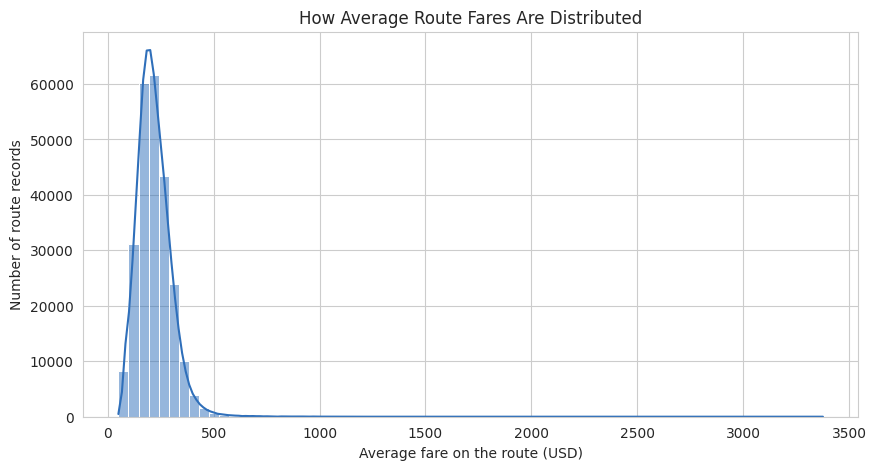

In [64]:
# Section 1.2: The target variable

print(flights_df['fare'].describe().round(2))
print("Skewness of fare:", round(flights_df['fare'].skew(), 3))

plt.figure(figsize=(10, 5))
sns.histplot(flights_df['fare'], bins=70, kde=True, color='#2F6FBA')
plt.title('How Average Route Fares Are Distributed')
plt.xlabel('Average fare on the route (USD)')
plt.ylabel('Number of route records')
plt.savefig('01_fare_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Fares run from $50 to $3,377 with a median of $209.32 and a mean of $218.98.
# The mean sits above the median, which tells us a small number of very expensive routes are pulling the average up.
# The skewness printed above is 2.381. A perfectly symmetric bell curve has a skewness of 0, so 2.381 means the data leans heavily to the right.


Section 2 : Data cleaning and Preparation

In [65]:
# Section 2.1: Missing values

missing_counts = flights_df.isnull().sum()
missing_percent = (missing_counts / len(flights_df) * 100).round(2)

print("Columns with missing values:")
print(pd.DataFrame({'missing': missing_counts[missing_counts > 0],
                    'percent': missing_percent[missing_counts > 0]}).to_string())

# Geocoded_City1 & Geocoded_City2 (~16% missing):
# We don't use these columns anywhere in our analysis, so we leave them alone.
# Dropping 16% of our entire dataset for unused fields isn't worth it.

# carrier_lg & carrier_low (~0.65% missing):
# We need these for key model inputs in Sections 3.1 and 5.1.
# Since airline names are text, we can't just fill them with averages.
# Because it's under 1% of our data, we safely drop these rows in Section 2.4(null rows).

Columns with missing values:
                missing  percent
carrier_lg         1540     0.63
large_ms           1540     0.63
fare_lg            1540     0.63
carrier_low        1612     0.66
lf_ms              1612     0.66
fare_low           1612     0.66
Geocoded_City1    39206    15.94
Geocoded_City2    39206    15.94


In [66]:
# Section 2.2: Duplicate rows

print("Exact duplicate rows:", flights_df.duplicated().sum())
print("Duplicate primary keys (tbl1apk):", flights_df['tbl1apk'].duplicated().sum())

# Zero exact duplicates and zero duplicate primary keys.
# We still run this check because a duplicated route would let the same record appear in both our training set and our test set, which would make our accuracy look better than it really is.

Exact duplicate rows: 0
Duplicate primary keys (tbl1apk): 0


In [67]:
# Section 2.3: DATA LEAKAGE CHECK - the most important step before modelling

fare_correlations = flights_df[['fare', 'fare_lg', 'fare_low', 'nsmiles', 'passengers',
                                'large_ms', 'lf_ms', 'Year']].corr()['fare']
print("How strongly each column moves with fare:")
print(fare_correlations.round(3).sort_values(ascending=False).to_string())

flights_df = flights_df.drop(columns=['fare_lg', 'fare_low'])
print("Columns left after dropping fare_lg and fare_low:", flights_df.shape[1])

# fare_lg moves with fare at 0.956 and fare_low at 0.875, far ahead of anything else.
# That looks great until you read what those columns actually are.
# fare_lg is the fare charged by the biggest airline on the route and fare_low is the fare charged by the cheapest one, and our target fare is basically a blend of the two.
# Using them would mean working out an average from the very numbers that average is made of, which is not prediction at all.

# So we remove both columns here, before any model exists that could use them by mistake. This took the column count from 23 down to 21.

# We keep large_ms and lf_ms. Those are market SHARES, which describe how much competition a route has without containing any price, so they are fair to use.

How strongly each column moves with fare:
fare          1.000
fare_lg       0.956
fare_low      0.875
nsmiles       0.500
Year          0.151
passengers   -0.171
large_ms     -0.182
lf_ms        -0.189
Columns left after dropping fare_lg and fare_low: 21


Routes with 0 passengers   : 7439
Routes with fare above $1,500: 17
Routes with 0 miles        : 0
Rows with no entries for largest airline column: 1540
Rows with no entries for cheapest airline column: 1612
Rows before cleaning: 245955
Rows after cleaning : 237985
Rows removed        : 7970 (3.24%)
Longest route we kept (miles): 2724
Busiest route we kept (daily passengers): 8301
Skewness of fare now: 0.79


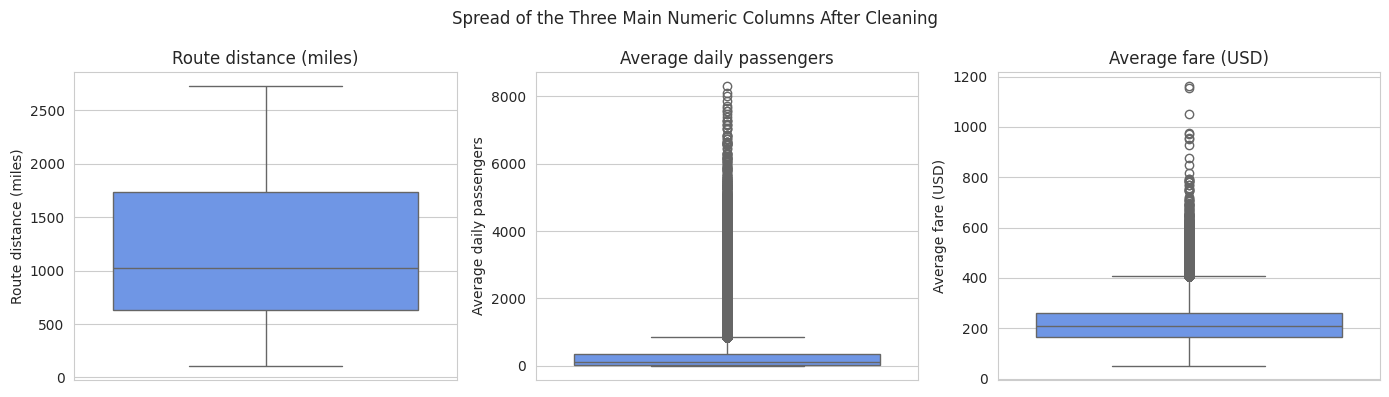

In [68]:
# Section 2.4: Finding impossible, implausible values and applying all the row filters

print("Routes with 0 passengers   :", (flights_df['passengers'] == 0).sum())
print("Routes with fare above $1,500:", (flights_df['fare'] > 1500).sum())
print("Routes with 0 miles        :", (flights_df['nsmiles'] == 0).sum())
print("Rows with no entries for largest airline column:", flights_df['carrier_lg'].isnull().sum())
print("Rows with no entries for cheapest airline column:", flights_df['carrier_low'].isnull().sum())

rows_before = len(flights_df)

flights_df = flights_df.dropna(subset=['carrier_lg', 'carrier_low'])
flights_df = flights_df[flights_df['passengers'] > 0]
flights_df = flights_df[flights_df['fare'] <= 1500]

print("Rows before cleaning:", rows_before)
print("Rows after cleaning :", len(flights_df))
print("Rows removed        :", rows_before - len(flights_df),
      "(" + str(round((rows_before - len(flights_df)) / rows_before * 100, 2)) + "%)")
print("Longest route we kept (miles):", flights_df['nsmiles'].max())
print("Busiest route we kept (daily passengers):", flights_df['passengers'].max())
print("Skewness of fare now:", round(flights_df['fare'].skew(), 3))

plt.figure(figsize=(14, 4))
axis_names = {'nsmiles': 'Route distance (miles)',
              'passengers': 'Average daily passengers',
              'fare': 'Average fare (USD)'}
for position, column in enumerate(['nsmiles', 'passengers', 'fare'], start=1):
    plt.subplot(1, 3, position)
    sns.boxplot(y=flights_df[column], color='#5B8FF9')
    plt.title(axis_names[column])
    plt.ylabel(axis_names[column])
plt.suptitle('Spread of the Three Main Numeric Columns After Cleaning')
plt.tight_layout()
plt.savefig('02_outliers_before.png', dpi=300, bbox_inches='tight')
plt.show()


# We removed 7,970 rows, which is 3.24% of the file, for three reasons.
# 7,439 routes carried zero passengers, so there is no real market fare to learn from.
# 17 routes report an average above $1,500, which are premium-cabin averages on very thin routes that would pull our model upward.
# About 1,600 rows have no named airline, and we need that for our model inputs.

# The skewness of the fare has dropped from 2.381 to 0.790 now that the 17 extreme routes are gone.

# We deliberately kept the extremes that are real. The longest route we kept is 2,724 miles and the busiest carries 8,301 passengers a day.
# Those are genuine routes an airline flies, and a model that has never seen a coast-to-coast route would price one badly.

In [69]:
# Section 3.1: Two new columns we build for the models

busiest_airlines = flights_df['carrier_lg'].value_counts().head(10).index
flights_df['airline_group'] = np.where(flights_df['carrier_lg'].isin(busiest_airlines),
                                       flights_df['carrier_lg'], 'Other')

budget_airlines = ['WN', 'B6', 'NK', 'F9', 'G4', 'FL', 'U5']
flights_df['is_budget_airline'] = flights_df['carrier_lg'].isin(budget_airlines).astype(int)

print("Total airlines in the file:", flights_df['carrier_lg'].nunique())
print("Airline groups we keep    :", flights_df['airline_group'].nunique())
print("Routes by airline group:")
print(flights_df['airline_group'].value_counts().to_string())
print("Routes led by a budget airline:", flights_df['is_budget_airline'].sum())
print("Routes led by a legacy airline:", (flights_df['is_budget_airline'] == 0).sum())

# We build only two new columns and both of them go into the models.

# airline_group
# The file has 67 different airlines.
# After cleaning there are 64 different airlines left, but as the counts above show, most of them barely appear.
# A model cannot read an airline name as text,so every airline has to be turned into its own yes/no column.
# With 64 airlines that means 64 new columns and almost all of them would be full of zeros, which slows the model down and adds noise without adding anything useful.
# So we keep the 10 airlines that appear most often and label the rest "Other".
# That takes us from 64 groups down to 11.
# airlines that appear most often and label the rest "Other". That takes us from 64 groups down to 11.

# is_budget_airline
# Southwest, JetBlue, Spirit, Frontier and Allegiant run a different kind of business from American, Delta and United.
# They fly one type of aircraft, use cheaper secondary airports and sell a simpler ticket, and all of that shows up in the price.
# Instead of making the model work this out airline by airline, we mark each route with one yes/no column saying
# whether the biggest airline on it is a budget airline.
# Section 4.4 shows this single column is worth about $40 a ticket, which is why it earns its place.

Total airlines in the file: 64
Airline groups we keep    : 11
Routes by airline group:
airline_group
WN       58509
AA       44273
DL       33016
UA       29371
US       24665
CO       13768
Other    13587
NW        7021
B6        6105
AS        4100
HP        3570
Routes led by a budget airline: 72318
Routes led by a legacy airline: 165667


Median fare for each distance band:
nsmiles
Under 500       162.23
500 to 1000     187.25
1000 to 1500    208.17
1500 to 2000    246.08
Over 2000       279.96

Correlation between distance and fare: 0.548
Cheapest fare at 900 to 1100 miles: $ 64.91
Most Expensive fare at 900 to 1100 miles : $ 668.2


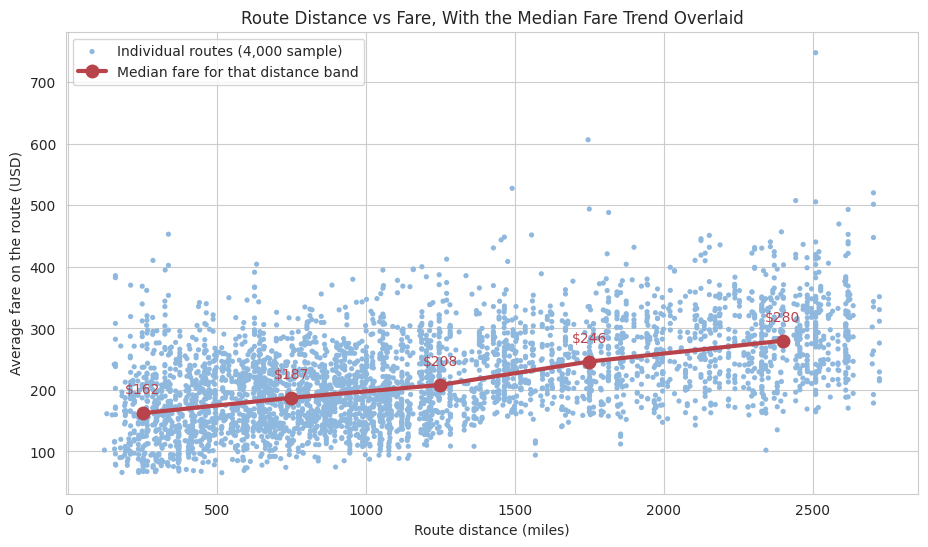

In [70]:
# Section 4.1: Chart 1 - Does distance explain the fare?

route_sample = flights_df.sample(4000, random_state=42)
distance_band = pd.cut(flights_df['nsmiles'], bins=[0, 500, 1000, 1500, 2000, 3000],
                       labels=['Under 500', '500 to 1000', '1000 to 1500',
                               '1500 to 2000', 'Over 2000'])
median_by_distance = flights_df.groupby(distance_band, observed=True)['fare'].median()
band_midpoints = [250, 750, 1250, 1750, 2400]

print("Median fare for each distance band:")
print(median_by_distance.round(2).to_string())
print()
print("Correlation between distance and fare:",
      round(flights_df['nsmiles'].corr(flights_df['fare']), 3))
print("Cheapest fare at 900 to 1100 miles: $",
      round(flights_df[flights_df['nsmiles'].between(900, 1100)]['fare'].min(), 2))
print("Most Expensive fare at 900 to 1100 miles : $",
      round(flights_df[flights_df['nsmiles'].between(900, 1100)]['fare'].max(), 2))

plt.figure(figsize=(11, 6))
plt.scatter(route_sample['nsmiles'], route_sample['fare'], s=14, color='#8FB8DE',
            edgecolor='none', label='Individual routes (4,000 sample)')
plt.plot(band_midpoints, median_by_distance.values, color='#B8434A', marker='o',
         linewidth=3, markersize=9, label='Median fare for that distance band')
for x_position, y_value in zip(band_midpoints, median_by_distance.values):
    plt.annotate("$" + str(round(y_value)), (x_position, y_value),
                 textcoords='offset points', xytext=(0, 14), ha='center',
                 fontsize=10, color='#B8434A')
plt.title('Route Distance vs Fare, With the Median Fare Trend Overlaid')
plt.xlabel('Route distance (miles)')
plt.ylabel('Average fare on the route (USD)')
plt.legend()
plt.savefig('03_distance_vs_fare.png', dpi=300, bbox_inches='tight')
plt.show()

# We use this analysis if the flight distance alone is enough to predict ticket fares.
# Median fare climbs steadily with distance, from $162.23 under 500 miles to $279.96 over 2,000 miles.
# But the correlation printed above is only 0.548, it shows distance clearly influences price but it doesn't strictly dictate it.
# Distance sets a floor under the price, it does not set the price.
# This is exactly why our distance-only model in Section 5.2 does so badly.

Year
1993    212.66
2000    215.80
2010    211.20
2019    239.74
2020    192.17
2024    255.18


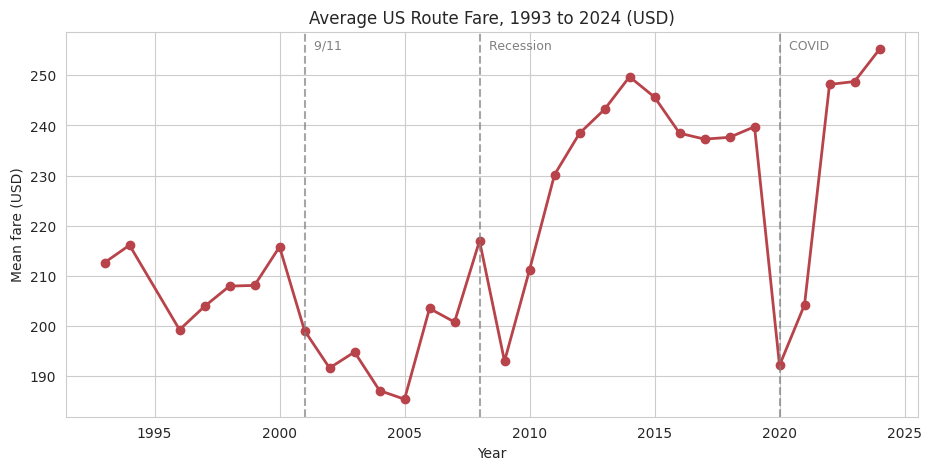

In [71]:
# Section 4.2: Chart 2 - How have fares moved over 31 years?

yearly = flights_df.groupby('Year')['fare'].mean()

print(yearly.reindex([1993, 2000, 2010, 2019, 2020, 2024]).round(2).to_string())

plt.figure(figsize=(11, 5))
plt.plot(yearly.index, yearly.values, marker='o', linewidth=2, color='#B8434A')
plt.axvline(2001, color='grey', linestyle='--', alpha=0.7)
plt.axvline(2008, color='grey', linestyle='--', alpha=0.7)
plt.axvline(2020, color='grey', linestyle='--', alpha=0.7)
plt.text(2001.2, yearly.max(), ' 9/11', fontsize=9, color='grey')
plt.text(2008.2, yearly.max(), ' Recession', fontsize=9, color='grey')
plt.text(2020.2, yearly.max(), ' COVID', fontsize=9, color='grey')
plt.title('Average US Route Fare, 1993 to 2024 (USD)')
plt.xlabel('Year')
plt.ylabel('Mean fare (USD)')
plt.savefig('04_fares_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

# This analysis shows us that the prices are heavily influenced by major economic shocks(time).
# The mean fare was $212.66 in 1993 and $255.18 in 2024.
# That is only a 20% rise across 31 years, while general US consumer prices roughly doubled over the same period. In real terms air travel got dramatically cheaper.
# The lowest year in the whole series is 2020 at $192.17, which is the COVID collapse, and the highest is 2024 at $255.18 as the market recovered.
# In predictive modelling, if we try to estimate flight fares using only spatial route features(like distance, origin/destination airports) while ignoring time,
# the model will evaluate a 1993 route and 2024 route identically.


Fares by airline group:
                 mean  median  count
airline_group                       
Other          154.23  144.32  13587
AS             180.15  168.24   4100
B6             188.19  179.55   6105
WN             195.19  190.79  58509
HP             198.86  193.14   3570
CO             206.92  199.72  13768
US             212.13  204.30  24665
NW             217.14  211.84   7021
DL             231.44  222.26  33016
UA             249.05  239.45  29371
AA             247.08  239.96  44273
Gap between the most expensive and cheapest named airline: $ 71.72


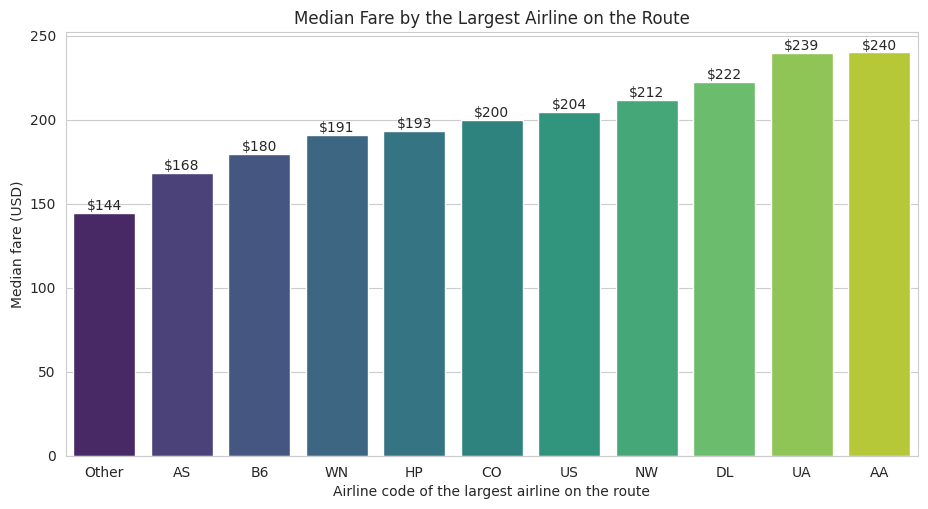

In [72]:
# Section 4.3: Chart 3 - Which airlines charge the most?

fare_by_airline = flights_df.groupby('airline_group')['fare'].agg(['mean', 'median', 'count'])
fare_by_airline = fare_by_airline.sort_values('median')

print("Fares by airline group:")
print(fare_by_airline.round(2).to_string())
print("Gap between the most expensive and cheapest named airline: $",
      round(fare_by_airline['median'].max() - fare_by_airline.drop('Other')['median'].min(), 2))

plt.figure(figsize=(11, 5.5))
airline_chart = sns.barplot(x=fare_by_airline.index, y=fare_by_airline['median'],
                            hue=fare_by_airline.index, palette='viridis', legend=False)
for bar_group in airline_chart.containers:
    airline_chart.bar_label(bar_group, fmt='$%.0f')
plt.title('Median Fare by the Largest Airline on the Route')
plt.xlabel('Airline code of the largest airline on the route')
plt.ylabel('Median fare (USD)')
plt.savefig('05_fare_by_airline.png', dpi=300, bbox_inches='tight')
plt.show()


# This analysis shows us why distance alone doesn't determine fare, who operates the route matter immensely.
# This chart proves that different airlines operating over similar distances charge fundamentally different prices based on their business model.
# American (AA) at $240 and United (UA) at $239 sit at the top.
# Alaska (AS) at $168 and JetBlue (B6) at $180 sit at the bottom of the named airlines, with Southwest (WN) at $191 just above them.
# The gap between the expensive and cheapest named airline is $71.72 on the median route, which makes airline identity one of the strongest signals in the data.
# The "Other" group is lowest of all at $144 because it is mostly small regional carriers flying short cheap routes.


Fares by type of airline:
                  mean  median   count
Legacy airline  229.02  220.34  165667
Budget airline  189.07  184.20   72318
Difference in mean fare: $ 39.95
Budget fares are lower by: 17.4%


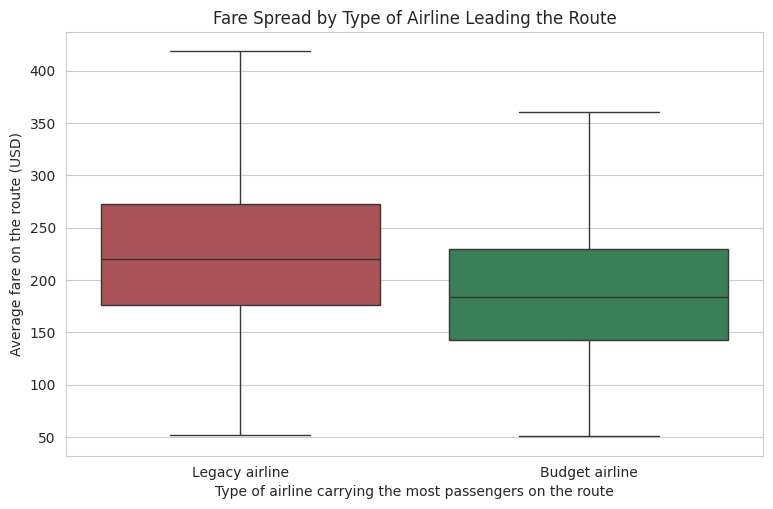

In [73]:
# Section 4.4: Chart 4 - The budget-airline effect

fare_by_type = flights_df.groupby('is_budget_airline')['fare'].agg(['mean', 'median', 'count'])
fare_by_type.index = ['Legacy airline', 'Budget airline']

print("Fares by type of airline:")
print(fare_by_type.round(2).to_string())
print("Difference in mean fare: $",
      round(fare_by_type.loc['Legacy airline', 'mean'] - fare_by_type.loc['Budget airline', 'mean'], 2))
print("Budget fares are lower by:",
      str(round((1 - fare_by_type.loc['Budget airline', 'mean'] /
                 fare_by_type.loc['Legacy airline', 'mean']) * 100, 1)) + "%")

plt.figure(figsize=(9, 5.5))
sns.boxplot(data=flights_df, x='is_budget_airline', y='fare', hue='is_budget_airline',
            palette=['#B8434A', '#2E8B57'], showfliers=False, legend=False)
plt.xticks([0, 1], ['Legacy airline', 'Budget airline'])
plt.title('Fare Spread by Type of Airline Leading the Route')
plt.xlabel('Type of airline carrying the most passengers on the route')
plt.ylabel('Average fare on the route (USD)')
plt.savefig('06_budget_airline_effect.png', dpi=300, bbox_inches='tight')
plt.show()


# When a budget airline is the biggest operator the mean fare is $189.07.
# When a legacy airline is biggest it is $229.02.
# That is a gap of $39.95, or 17.4% cheaper.
# For an airport authority trying to bring local fares down, this says that
# attracting one budget airline does more than any amount of negotiating with the airline already there.


Median fare by how concentrated the route is:
large_ms
Competitive under 40%     229.95
Moderate 40 to 60%        217.31
Concentrated 60 to 80%    212.09
Near monopoly over 80%    189.89
Correlation between market share and fare: -0.218
Share of near-monopoly routes led by a budget airline: 43.8%
Share of competitive routes led by a budget airline  : 19.1%


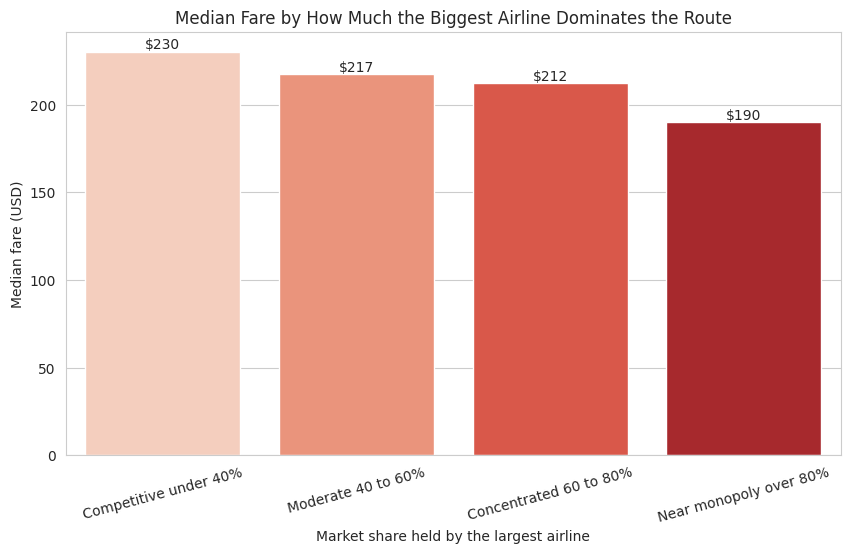

In [74]:
# Section 4.5: Chart 5 - Does less competition mean higher fares?

concentration = pd.cut(flights_df['large_ms'], bins=[0, 0.4, 0.6, 0.8, 1.0],
                       labels=['Competitive under 40%', 'Moderate 40 to 60%',
                               'Concentrated 60 to 80%', 'Near monopoly over 80%'])
fare_by_concentration = flights_df.groupby(concentration, observed=True)['fare'].median()

print("Median fare by how concentrated the route is:")
print(fare_by_concentration.round(2).to_string())
print("Correlation between market share and fare:",
      round(flights_df['large_ms'].corr(flights_df['fare']), 3))
print("Share of near-monopoly routes led by a budget airline:",
      str(round(flights_df[flights_df['large_ms'] > 0.8]['is_budget_airline'].mean() * 100, 1)) + "%")
print("Share of competitive routes led by a budget airline  :",
      str(round(flights_df[flights_df['large_ms'] < 0.4]['is_budget_airline'].mean() * 100, 1)) + "%")

plt.figure(figsize=(10, 5.5))
concentration_chart = sns.barplot(x=fare_by_concentration.index, y=fare_by_concentration.values,
                                  hue=fare_by_concentration.index, palette='Reds', legend=False)
for bar_group in concentration_chart.containers:
    concentration_chart.bar_label(bar_group, fmt='$%.0f')
plt.title('Median Fare by How Much the Biggest Airline Dominates the Route')
plt.xlabel('Market share held by the largest airline')
plt.ylabel('Median fare (USD)')
plt.xticks(rotation=15)
plt.savefig('07_competition_effect.png', dpi=300, bbox_inches='tight')
plt.show()

# This chart analysis how market share of largest airline on a route impacts ticket prices, decides budget airline presence across competitive vs. monopoly routes.
# The correlation is -0.218, meaning fares are LOWER on routes where one airline dominates, which is the opposite of what basic economics would predict.
# The median falls steadily from $229.95 on competitive routes to $189.89 on near-monopoly ones, a drop of $40.06.
# The two percentages printed above explain it. Budget airlines lead 43.8% of near monopoly routes but only 19.1% of competitive ones.
# Budget carriers tend to pick a route, take most of it, and price it aggressively.
# So a dominated route here is often a cheap monopoly rather than an expensive one.


How strongly each column moves with fare:
fare          1.000
nsmiles       0.548
Year          0.173
quarter      -0.029
passengers   -0.177
large_ms     -0.218
lf_ms        -0.234


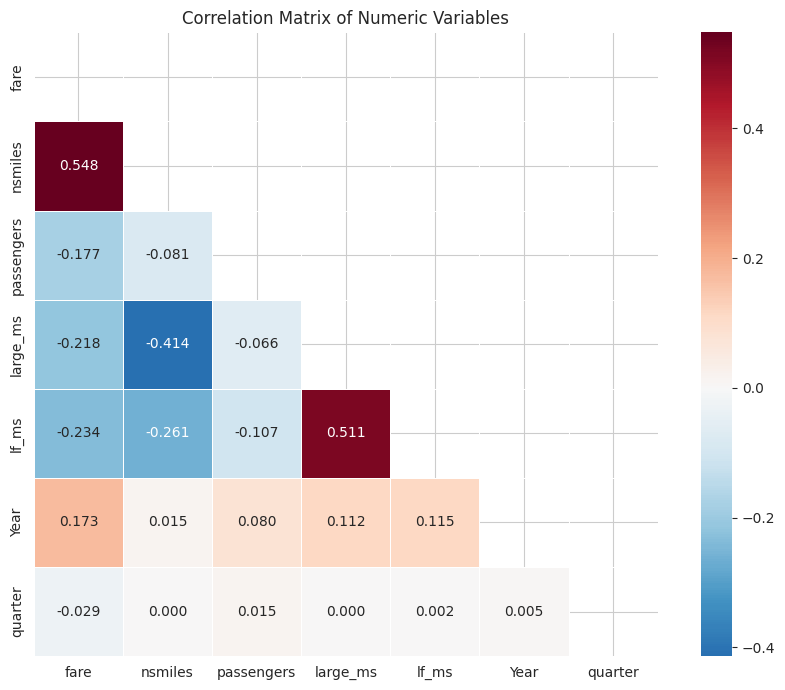

In [75]:
#Section 4.6: Chart 6 - Correlation heatmap

numeric_cols = ['fare', 'nsmiles', 'passengers', 'large_ms', 'lf_ms', 'Year', 'quarter']
corr_matrix = flights_df[numeric_cols].corr()

print("How strongly each column moves with fare:")
print(corr_matrix['fare'].sort_values(ascending=False).round(3).to_string())

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, mask=np.triu(np.ones_like(corr_matrix, dtype=bool)),
            cmap='RdBu_r', center=0, annot=True, fmt='.3f', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numeric Variables')
plt.tight_layout()
plt.savefig('08_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Until now , all the above charts evaluated a single variable against price. This heatmap serves as a executive summary showing how all NUMERIC METRICS interact simultaneously.
# Flight distance (nsmiles) is the strongest single driver of ticket prices, with a moderate positive correlation of 0.548.
# Higher market share and passenger volume show weak negative correlations with fare (-0.18 to -0.23), likely reflecting lower prices on heavily traveled or competitive routes.
# Since no single feature explains fare prices on its own, a multi-variable model will be necessary to capture the full picture.

Median fare by route distance and daily passengers:
passengers    Thin <50  Light 50-200  Busy 200-500  Trunk 500+
nsmiles                                                       
Under 500       193.21        175.26        148.03      125.10
500 to 1000     204.86        187.14        184.15      167.49
1000 to 1500    231.83        202.01        201.34      189.03
1500 to 2000    259.02        242.35        242.16      232.59
Over 2000       292.38        270.98        262.08      281.10
Cheapest square in the grid: $ 125.11
Most Expensive square in the grid : $ 292.38


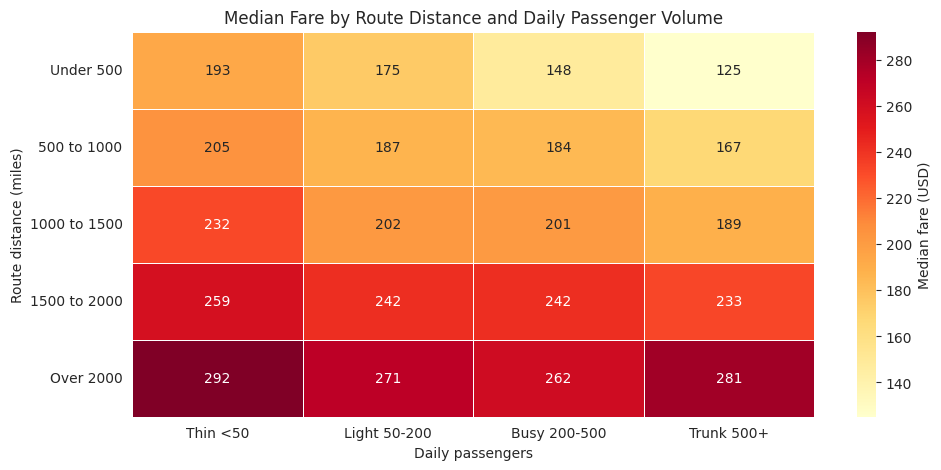

In [76]:
#Section 4.7: Chart 7 - Distance and passenger together

passenger_band = pd.cut(flights_df['passengers'], bins=[0, 50, 200, 500, 10000],
                        labels=['Thin <50', 'Light 50-200', 'Busy 200-500', 'Trunk 500+'])
fare_grid = flights_df.pivot_table(index=distance_band, columns=passenger_band,
                               values='fare', aggfunc='median', observed=True)
print("Median fare by route distance and daily passengers:")
print(fare_grid.round(2).to_string())
print("Cheapest square in the grid: $", round(fare_grid.min().min(), 2))
print("Most Expensive square in the grid : $", round(fare_grid.max().max(), 2))
plt.figure(figsize=(11, 5))
sns.heatmap(fare_grid, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Median fare (USD)'})
plt.title('Median Fare by Route Distance and Daily Passenger Volume')
plt.xlabel('Daily passengers')
plt.ylabel('Route distance (miles)')
plt.savefig('09_distance_traffic_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


# Read across any row and fares fall as the route gets busier - airlines use larger aircraft and experience high competition, lowering operating costs per seat.
# Read down any column and fares rise as the route gets longer - Low demand forces airlines to fly smaller planes wuth fewer seats filled, raising operating costs per passenger.
# The cheapest square in the grid is $125.10, for a short busy route, and the
# most expensive is $292.38, for a long thin one.


In [77]:
# Section 5.1: Build the feature set and split the data

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_columns = ['Year', 'quarter', 'nsmiles', 'passengers',
                 'large_ms', 'lf_ms', 'airline_group', 'is_budget_airline']

flights_X = pd.get_dummies(flights_df[model_columns], drop_first=True)
flights_y = flights_df['fare']

# Partition data (70% training, 30% testing, random state=42)
X_train, X_test, y_train, y_test = train_test_split(flights_X, flights_y,
                                                    test_size=0.3, random_state=42)

print("Training set size :", X_train.shape[0])
print("Testing set size  :", X_test.shape[0])
print("Number of inputs  :", flights_X.shape[1])
print()

baseline_guess = [y_train.mean()] * len(y_test)
baseline_mae = mean_absolute_error(y_test, baseline_guess)
print("Baseline: always guess the average fare of $", round(y_train.mean(), 2))
print("Baseline average miss: $", round(baseline_mae, 2))

model_scores = []

def score_model(model_name, actual_fares, predicted_fares, what_changed):
    average_miss = mean_absolute_error(actual_fares, predicted_fares)
    typical_miss = np.sqrt(mean_squared_error(actual_fares, predicted_fares))
    variation_explained = r2_score(actual_fares, predicted_fares)
    this_score = {'Model': model_name,
                         'Average miss (USD)': round(average_miss, 2),
                         'RMSE (USD)': round(typical_miss, 2),
                         'R-squared': round(variation_explained, 4),
                         'What changed': what_changed}

    already_scored = [position for position, row in enumerate(model_scores)
                      if row['Model'] == model_name]
    if already_scored:
        model_scores[already_scored[0]] = this_score
    else:
        model_scores.append(this_score)
    model_scores.sort(key=lambda row: row['Model'])
    print(model_name)
    print("   Average miss (MAE) = $", round(average_miss, 2))
    print("   RMSE               = $", round(typical_miss, 2))
    print("   R-squared          =", round(variation_explained, 4))
    return average_miss, variation_explained

# We have done 70% training and 30% testing.
# fare_lg and fare_low are absent from base_features. That is the leakage decision from Section 2.3 being enforced in code.
# Every model built after Section 5.1 exists to : drive that MAE/RMSE error down as far below the baseline as possible while pushing R2 as close to 1.0 as possible.
# An analyst with no model at all misses by $58.01 per route. Every model below has to beat that number or it is not worth building.

Training set size : 166589
Testing set size  : 71396
Number of inputs  : 17

Baseline: always guess the average fare of $ 216.92
Baseline average miss: $ 58.01


M1: distance only
   Average miss (MAE) = $ 48.41
   RMSE               = $ 61.69
   R-squared          = 0.3048
Extra dollars per mile flown: $ 0.0581
Improvement over naive average baseline model: $ 9.59


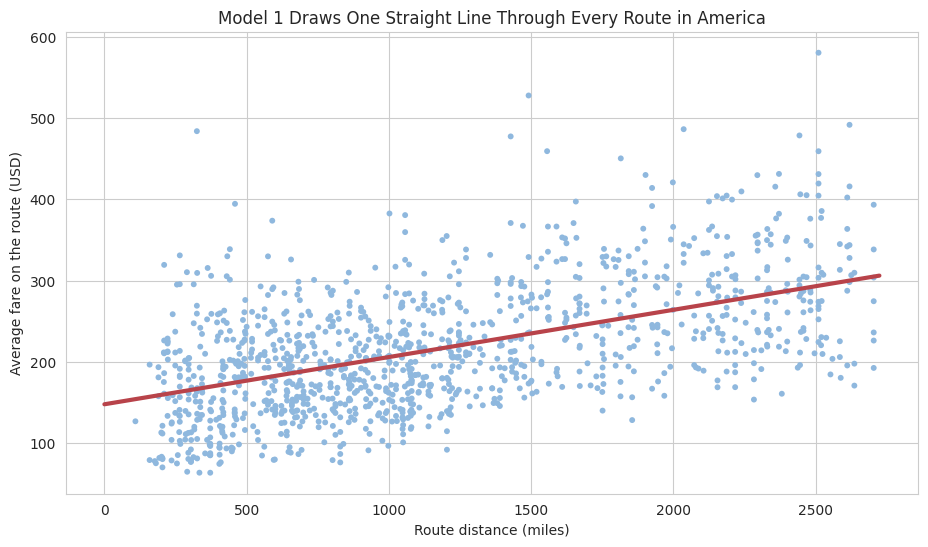

In [78]:
#Section 5.2: MODEL 1 - Simple linear regression using distance only
#This is the naive approach: longer flight, higher fare.

simple_model = LinearRegression()
simple_model.fit(X_train[['nsmiles']], y_train)
simple_predictions = simple_model.predict(X_test[['nsmiles']])

simple_miss, simple_r2 = score_model('M1: distance only', y_test, simple_predictions,
                                     'Starting point')
print("Extra dollars per mile flown: $", round(simple_model.coef_[0], 4))
print("Improvement over naive average baseline model: $", round(baseline_mae - simple_miss, 2))

plot_sample = X_test.sample(1200, random_state=42)
plot_actual = y_test.loc[plot_sample.index]
distance_line = pd.DataFrame({'nsmiles': np.linspace(0, X_test['nsmiles'].max(), 100)})

plt.figure(figsize=(11, 6))
plt.scatter(plot_sample['nsmiles'], plot_actual, s=18, color='#8FB8DE',
            edgecolor='none', label='Actual routes (1,200 sample)')
plt.plot(distance_line['nsmiles'], simple_model.predict(distance_line),
         color='#B8434A', linewidth=3, label='What Model 1 predicts')
plt.title('Model 1 Draws One Straight Line Through Every Route in America')
plt.xlabel('Route distance (miles)')
plt.ylabel('Average fare on the route (USD)')
plt.savefig('10_model1_failure.png', dpi=300, bbox_inches='tight')
plt.show()


# This model is deliberately weak and included to show where the error comes from.
# R-squared of 0.3048 means distance explains only 30% of the fare.
# The average miss is $48.41, against $58.01 for having no model at all.
# All that work bought us an improvement of $9.60 per route.

# At any point along the red line the real routes above and below it spread across hundreds of dollars, and the model has only one
# number to offer all of them.

In [79]:
# Section 5.3: MODEL 2 - Multiple linear regression using all the columns
# Now we give the model everything: year, quarter, distance, passengers, market shares, carrier and the low-cost flag.

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_predictions = multiple_model.predict(X_test)

multiple_miss, multiple_r2 = score_model('M2: all columns', y_test, multiple_predictions,
                                         'Added 7 more columns')

print("Improvement over Model 1: $", round(simple_miss - multiple_miss, 2))

print("The six columns that move the fare most, in dollars:")
airline_effects = pd.Series(multiple_model.coef_, index=flights_X.columns)
print(airline_effects.sort_values(key=abs, ascending=False).head(6).round(2).to_string())

# R-squared goes from 0.3048 to 0.4702 and the average miss falls
# from $48.41 to $40.98, an improvement of $7.43 per route.

# Being a budget-airline route takes $46.94 off the fare once everything else is held steady.
# An Alaska route is $43.96 below the reference airline.
# A higher share for the biggest airline adds $23.07 and a higher share for the cheapest airline takes off $19.61.

# We also tried predicting the logarithm of the fare, which is the standard fix
# when price data is lopsided. It made things worse, giving an average miss of
# $41.32 and R-squared of 0.4443, because the skewness of 0.790 we saw in
# Section 1.2 is mild and the logarithm overcorrects it. We are reporting that
# rather than quietly dropping an experiment that did not work.

M2: all columns
   Average miss (MAE) = $ 40.98
   RMSE               = $ 53.85
   R-squared          = 0.4702
Improvement over Model 1: $ 7.43
The six columns that move the fare most, in dollars:
is_budget_airline     -46.94
airline_group_AS      -43.96
airline_group_Other   -38.96
airline_group_HP      -36.65
large_ms               23.07
lf_ms                 -19.61


R-squared of Model 2: 0.4702
Share of fare differences still unexplained: 53.0%

Average miss on cheap routes under $150: $ 43.76
Average miss on dear routes over $400  : $ 167.74

Biggest amount we underpriced a route by: $ 876.96
Biggest amount we overpriced a route by : $ 208.12


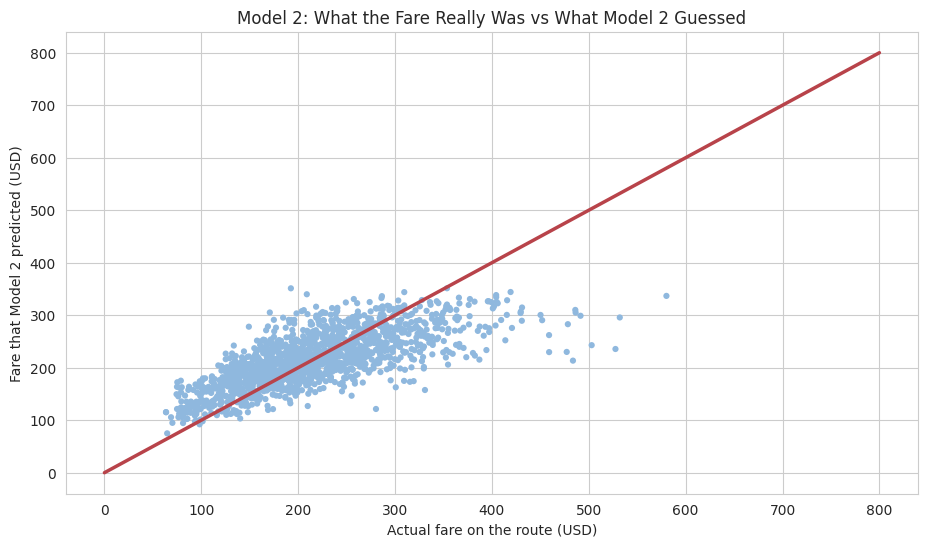

In [80]:
# Section 5.4: Where Model 2 still goes wrong

multiple_misses = y_test - multiple_predictions

print("R-squared of Model 2:", round(multiple_r2, 4))
print("Share of fare differences still unexplained:",
      str(round((1 - multiple_r2) * 100, 1)) + "%")
print()
print("Average miss on cheap routes under $150: $",
      round(mean_absolute_error(y_test[y_test < 150], multiple_predictions[y_test < 150]), 2))
print("Average miss on dear routes over $400  : $",
      round(mean_absolute_error(y_test[y_test > 400], multiple_predictions[y_test > 400]), 2))
print()
print("Biggest amount we underpriced a route by: $", round(multiple_misses.max(), 2))
print("Biggest amount we overpriced a route by : $", round(abs(multiple_misses.min()), 2))

check_sample = y_test.sample(1500, random_state=42)
check_predictions = pd.Series(multiple_predictions, index=y_test.index).loc[check_sample.index]

plt.figure(figsize=(11, 6))
plt.scatter(check_sample, check_predictions, s=20, color='#8FB8DE', edgecolor='none',
            label='Routes in the test set (1,500 sample)')
plt.plot([0, 800], [0, 800], color='#B8434A', linewidth=2.5,
         label='Where a perfect prediction would sit')
plt.title('Model 2: What the Fare Really Was vs What Model 2 Guessed')
plt.xlabel('Actual fare on the route (USD)')
plt.ylabel('Fare that Model 2 predicted (USD)')
plt.savefig('11_model2_miss.png', dpi=300, bbox_inches='tight')
plt.show()

# R-squared of 0.4702 means 53.0% of the differences in fare are still unexplained, which the first two lines above tell.

# The chart makes the problem easy to see. If the model were perfect every dot would sit on the red line.
# Instead the dots form a flat cloud that is much less steep than the line.
# On the left the dots sit above the line, meaning we charge too much for cheap routes.
# On the right they sit below it, meaning we do not charge enough for expensive ones.

# The numbers agree: we miss by $43.76 on routes under $150 but by $167.74 on routes over $400.


In [81]:
#Section 5.5: Model 3, decision tree, and what overfitting looks like

tree_model = DecisionTreeRegressor(max_depth=12, random_state=42)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

tree_miss, tree_r2 = score_model('M3: decision tree', y_test, tree_predictions,
                                 'Allows non-straight-line rules')

print("Improvement over Model 2: $", round(multiple_miss - tree_miss, 2))


overgrown_tree = DecisionTreeRegressor(random_state=42)
overgrown_tree.fit(X_train, y_train)
overgrown_predictions = overgrown_tree.predict(X_test)

print("Depth-limited tree (max_depth=12)")
print("   Score on data it trained on   :", round(tree_model.score(X_train, y_train), 4))
print("   Score on data it has not seen :", round(tree_r2, 4))

print("Tree with no depth limit")
print("   Score on data it trained on   :", round(overgrown_tree.score(X_train, y_train), 4))
print("   Score on data it has not seen :", round(r2_score(y_test, overgrown_predictions), 4))

# A tree can say something like "if the route is over 1,500 miles AND a budget
# airline runs it, then the fare sits in this range". A straight line can never
# say that, it can only add a fixed amount for each column.
# The average miss falls to $31.16 and R-squared rises to 0.6494, which beats both of our linear models by a clear margin.

# The second tree is a warning. With no depth limit it scores 0.9992 on the data
# it learned from, which looks almost perfect, but only 0.5958 on R-squared on data it has
# not seen, which is WORSE than our depth-limited tree at 0.6494. It memorised
# individual routes instead of learning general rules about pricing. That is why we cap the depth at 12.

M3: decision tree
   Average miss (MAE) = $ 31.16
   RMSE               = $ 43.81
   R-squared          = 0.6494
Improvement over Model 2: $ 9.82
Depth-limited tree (max_depth=12)
   Score on data it trained on   : 0.7035
   Score on data it has not seen : 0.6494
Tree with no depth limit
   Score on data it trained on   : 0.9992
   Score on data it has not seen : 0.5958


In [82]:
# Section 5.6: Model 4, random forest

forest_model = RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=-1)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_miss, forest_r2 = score_model('M4: random forest', y_test, forest_predictions,
                                     'Averages 80 trees')

print("Improvement over Model 3: $", round(tree_miss - forest_miss, 2))
print("Miss as a share of the median fare:",
      str(round(forest_miss / flights_df['fare'].median() * 100, 1)) + "%")

print("Which columns the forest leaned on most:")
column_importance = pd.Series(forest_model.feature_importances_, index=flights_X.columns)
print(column_importance.sort_values(ascending=False).head(6).round(4).to_string())

print("Share carried by the top three columns:",
      str(round(column_importance.sort_values(ascending=False).head(3).sum() * 100, 1)) + "%")

# A random forest builds 80 trees on random slices of the data and averages them.
# One tree can be quirky, eighty averaged together are stable.
# This is our final model. MAE of $22.25 and R2 of 0.7980, which on a typical $209 fare is a miss of about 11%.
# Three factors dominate: distance (0.4261), Year (0.1727) and passengers (0.1231), together carrying about 72% of the decision.
# Year being second is worth noting for a business audience. It means a pricing model trained on old data would be badly wrong today, so any airline using this approach has to retrain it regularly.

M4: random forest
   Average miss (MAE) = $ 22.25
   RMSE               = $ 33.25
   R-squared          = 0.798
Improvement over Model 3: $ 8.91
Miss as a share of the median fare: 10.6%
Which columns the forest leaned on most:
nsmiles              0.4261
Year                 0.1727
passengers           0.1231
large_ms             0.0665
lf_ms                0.0612
is_budget_airline    0.0548
Share carried by the top three columns: 72.2%


Models scored so far: 4
            Model  Average miss (USD)  RMSE (USD)  R-squared                   What changed
M1: distance only               48.41       61.69     0.3048                 Starting point
  M2: all columns               40.98       53.85     0.4702           Added 7 more columns
M3: decision tree               31.16       43.81     0.6494 Allows non-straight-line rules
M4: random forest               22.25       33.25     0.7980              Averages 80 trees
Average miss fell from $ 48.41 to $ 22.25
That is an improvement of 54% over Model 1
And an improvement of 62% over having no model at all


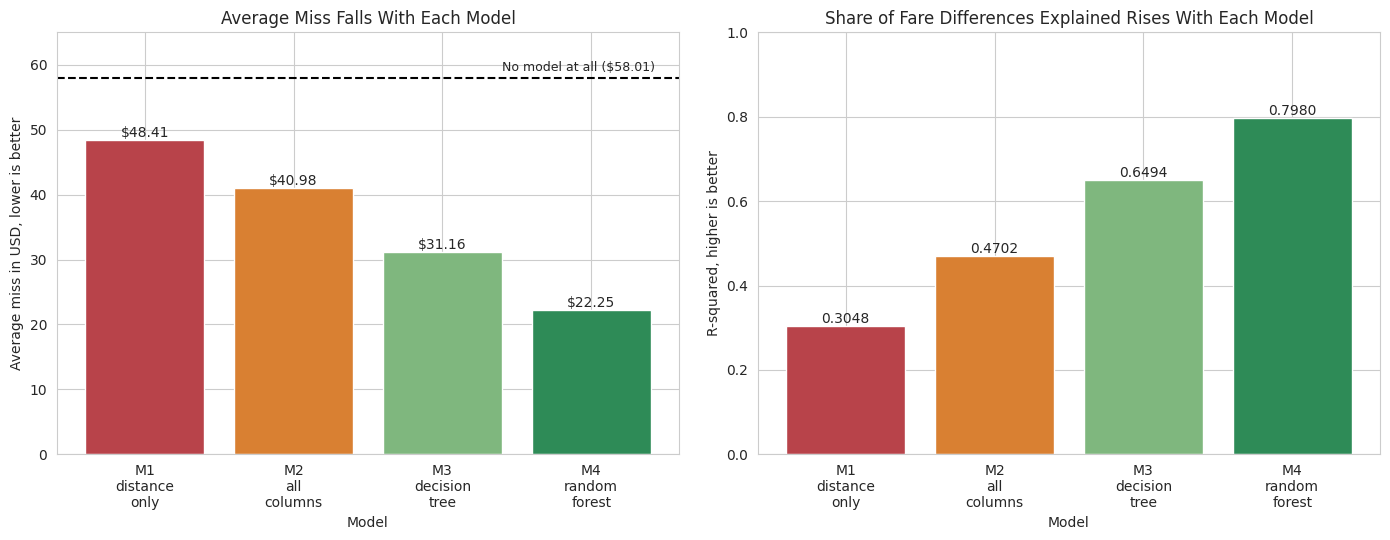

In [83]:
# Section 5.7: Comparing all four models

scores_table = pd.DataFrame(model_scores)
print("Models scored so far:", len(scores_table))
if len(scores_table) != 4:
    print("WARNING: expected 4 models. Use Runtime > Restart session and run all.")

print(scores_table.to_string(index=False))

print("Average miss fell from $", scores_table.iloc[0]['Average miss (USD)'],
      "to $", scores_table.iloc[-1]['Average miss (USD)'])
print("That is an improvement of",
      str(round((1 - scores_table.iloc[-1]['Average miss (USD)'] /
                 scores_table.iloc[0]['Average miss (USD)']) * 100)) + "% over Model 1")
print("And an improvement of",
      str(round((1 - scores_table.iloc[-1]['Average miss (USD)'] / baseline_mae) * 100)) +
      "% over having no model at all")

# Build the labels and colours FROM the results table rather than typing out a
# fixed list. If the table ever has a different number of rows, the chart still
# lines up instead of crashing.
short_names = {'M1: distance only': 'M1\ndistance\nonly',
               'M2: all columns': 'M2\nall\ncolumns',
               'M3: decision tree': 'M3\ndecision\ntree',
               'M4: random forest': 'M4\nrandom\nforest'}
model_labels = [short_names.get(row['Model'], row['Model']) for row in model_scores]
colour_choices = ['#B8434A', '#D98032', '#7FB77E', '#2E8B57']
bar_colours = [colour_choices[position % 4] for position in range(len(model_scores))]

plt.figure(figsize=(14, 5.5))

plt.subplot(1, 2, 1)
miss_bars = plt.bar(model_labels, [row['Average miss (USD)'] for row in model_scores],
                    color=bar_colours)
plt.bar_label(miss_bars, fmt='$%.2f')
plt.axhline(baseline_mae, color='black', linestyle='--')
plt.text(len(model_scores) - 1.6, baseline_mae + 1,
         'No model at all ($58.01)', fontsize=9)
plt.title('Average Miss Falls With Each Model')
plt.xlabel('Model')
plt.ylabel('Average miss in USD, lower is better')
plt.ylim(0, 65)

plt.subplot(1, 2, 2)
r2_bars = plt.bar(model_labels, [row['R-squared'] for row in model_scores], color=bar_colours)
plt.bar_label(r2_bars, fmt='%.4f')
plt.title('Share of Fare Differences Explained Rises With Each Model')
plt.xlabel('Model')
plt.ylabel('R-squared, higher is better')
plt.ylim(0, 1.0)

plt.tight_layout()
plt.savefig('12_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Each step is one specific fix.
#   M1 to M2  add the missing variables      $48.41 to $40.98
#   M2 to M3  allow non-linear rules         $40.98 to $31.16
#   M3 to M4  average 80 trees for stability $31.16 to $22.25

How close the final model gets:
   Within $20 of the real fare: 60.8% of routes
   Within $50 of the real fare: 89.9% of routes
Average miss on cheap routes under $150: $ 17.18
Average miss on dear routes over $400  : $ 85.06


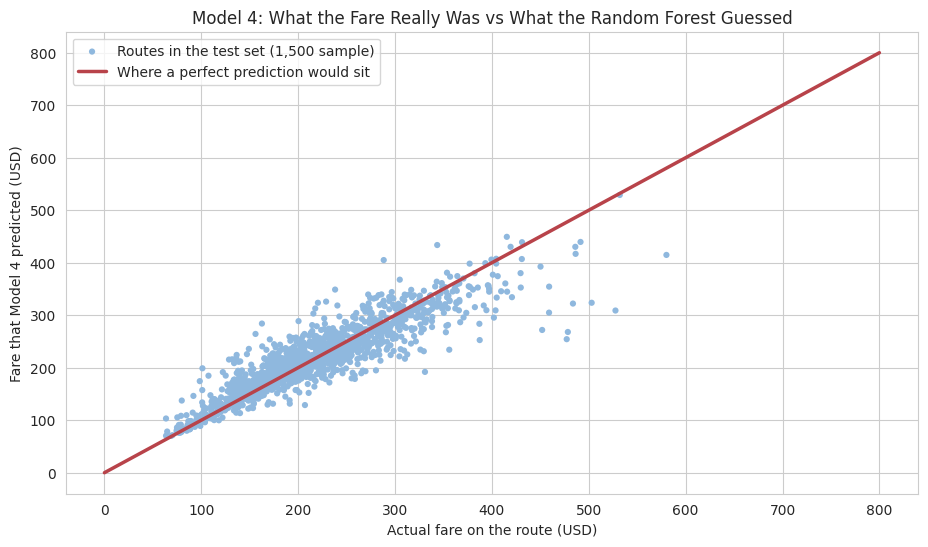

In [84]:
# Section 5.8: Final model diagnostics

forest_misses = y_test - forest_predictions

print("How close the final model gets:")
print("   Within $20 of the real fare:",
      str(round((abs(forest_misses) <= 20).mean() * 100, 1)) + "% of routes")
print("   Within $50 of the real fare:",
      str(round((abs(forest_misses) <= 50).mean() * 100, 1)) + "% of routes")

print("Average miss on cheap routes under $150: $",
      round(mean_absolute_error(y_test[y_test < 150], forest_predictions[y_test < 150]), 2))
print("Average miss on dear routes over $400  : $",
      round(mean_absolute_error(y_test[y_test > 400], forest_predictions[y_test > 400]), 2))

final_sample = y_test.sample(1500, random_state=42)
final_predictions = pd.Series(forest_predictions, index=y_test.index).loc[final_sample.index]

plt.figure(figsize=(11, 6))
plt.scatter(final_sample, final_predictions, s=20, color='#8FB8DE', edgecolor='none',
            label='Routes in the test set (1,500 sample)')
plt.plot([0, 800], [0, 800], color='#B8434A', linewidth=2.5,
         label='Where a perfect prediction would sit')
plt.title('Model 4: What the Fare Really Was vs What the Random Forest Guessed')
plt.xlabel('Actual fare on the route (USD)')
plt.ylabel('Fare that Model 4 predicted (USD)')
plt.legend()
plt.savefig('13_final_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()


#Compare the middle plot with Model 2's wide band in Section 5.4.
#The cloud is now a tight even band centred on zero, which is what a healthy regression model looks like.

In [85]:
# Section 6.1: Findings, limitations and what we would do next
print("KEY FINDINGS")
print("1. Distance sets a floor under the fare, not the fare itself. The")
print("   correlation is 0.548 and a distance-only model explains just 30% of")
print("   the differences between routes.")
print("2. Budget airlines lower the average route fare by $39.95, from $229.02 to $189.07")
print("3. Routes dominated by one airline are CHEAPER, not dearer (correlation")
print("   -0.218, median $229.95 down to $189.89), because budget airlines hold")
print("   near-monopoly routes against 18.7% of competitive ones.")
print("4. Year is the second most important column in the final model at 0.1727,")
print("   so a pricing model would need retraining regularly or it will drift.")
print("5. The final model misses by $22.25 on a typical route against $58.01 for")
print("   quoting the overall average, an improvement of 62%.")
print()
print("WHO BENEFITS")
print("   Airline pricing teams   check a fare before publishing it")
print("   Travel websites         tell users when a fare looks unusually high")
print("   Corporate travel buyers evidence when negotiating contract rates")
print("   Airport authorities     put a dollar figure on attracting a budget airline")
print()
print("OBSTACLES WE OVERCAME")
print("1. Data leakage. fare_lg and fare_low move with the target at 0.956 and")
print("   0.875 because the target is built from them. Leaving them in would")
print("   have given us a fake R-squared above 0.95.")
print("2. An experiment that failed. Taking the logarithm of the fare is the")
print("   normal fix for lopsided price data but it made our model worse")
print("3. Too many airlines. 64 airlines would have meant 64 mostly empty")
print("   columns, so we kept the 10 biggest and grouped the rest.")
print("4. Overfitting. A tree with no depth limit scored 0.9992 on its own")
print("   training data but only 0.5958 on data it had not seen.")
print()
print("LIMITATIONS")
print("1. These are quarterly averages for a whole route, not individual tickets,")
print("   so we cannot model booking date, day of week or cabin class.")
print("2. Fares are in the dollars of their own year, not adjusted for inflation.")
print("3. We have no cost data, so we know what airlines charged but not whether")
print("   the route made money.")
print("4. US domestic routes only, so none of this transfers to international flying.")
print()
print("WHAT WE WOULD DO DIFFERENTLY")
print("1. Use cross-validation instead of a single train and test split.")
print("2. Train on 1993 to 2019 and test on 2020 to 2024, which is a harder and")
print("   more realistic test for something meant to forecast.")
print("3. Tune the random forest instead of accepting the default settings.")
print()
print("WHAT EXTRA DATA WOULD HELP")
print("   Individual ticket sales with booking dates, aircraft type and seat")
print("   counts, quarterly jet fuel prices, and an inflation index.")
print()
print("HOW AI TOOLS SUPPORTED THIS PROJECT")
print("   We used AI help for chart formatting and for working out why the")
print("   logarithm experiment failed. Every number above comes from the code")
print("   in this notebook.")

KEY FINDINGS
1. Distance sets a floor under the fare, not the fare itself. The
   correlation is 0.548 and a distance-only model explains just 30% of
   the differences between routes.
2. Budget airlines lower the average route fare by $39.95, from $229.02 to $189.07
3. Routes dominated by one airline are CHEAPER, not dearer (correlation
   -0.218, median $229.95 down to $189.89), because budget airlines hold
   near-monopoly routes against 18.7% of competitive ones.
4. Year is the second most important column in the final model at 0.1727,
   so a pricing model would need retraining regularly or it will drift.
5. The final model misses by $22.25 on a typical route against $58.01 for
   quoting the overall average, an improvement of 62%.

WHO BENEFITS
   Airline pricing teams   check a fare before publishing it
   Travel websites         tell users when a fare looks unusually high
   Corporate travel buyers evidence when negotiating contract rates
   Airport authorities     put a dollar